# HDT 5: Árboles, Selección de Modelos y Bosques

**Ciencia de Datos, Sección A** · Asignada: martes 29 de septiembre · **Entrega: martes 6 de octubre, 23:59**

**Nombre:** Milton Orlando Beltran

Completar las celdas marcadas con `# ¿Qué va aquí?`. Cada ejercicio incluye una verificación comentada: descomentar para comprobar el resultado. Antes de entregar: **Kernel → Restart & Run All** (un notebook que no corre de arriba a abajo pierde 0.5 pts).

AI: resolver sin AI. Si se usó para entender un concepto, anotarlo en la bitácora del final (no penaliza).

## Setup

Dependencias: `pip install numpy pandas matplotlib scikit-learn`. Todo es determinista (semillas fijas y split fijo): las verificaciones son exactas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, ROJO, GRIS, LINEA = "#3A6EA5", "#B04A2E", "#75808E", "#E0E4EA"

def eje_limpio(ax):
    ax.grid(color=LINEA, lw=0.6, alpha=0.7)
    ax.spines[["top", "right"]].set_visible(False)

## Los datos

Un gimnasio quiere saber qué socios van a darse de baja. Historial de 1,000 socios: `visitas` (al mes), `meses` (antigüedad como socio), `cuota` (quetzales al mes) y `se_va` (1 = no renovó). El mismo tipo de problema que la mora del banco de las sesiones 15 a 17, con otro negocio.

La celda genera los datos completa; no hay nada que llenar aquí.

In [2]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(5)
n = 1000
visitas = np.minimum(rng.poisson(8, n), 30)
meses = rng.integers(1, 49, n)
cuota = rng.normal(400, 90, n).clip(200, 700).round(0)

riesgo = (-2.4 + 1.6 * (visitas <= 5) + 1.1 * (meses <= 12)
          + 0.9 * (cuota >= 480) + 1.1 * ((visitas <= 5) & (meses <= 12)))
se_va = (rng.random(n) < 1 / (1 + np.exp(-riesgo))).astype(int)

df = pd.DataFrame({"visitas": visitas, "meses": meses, "cuota": cuota, "se_va": se_va})
columnas = ["visitas", "meses", "cuota"]
X_train, X_test, y_train, y_test = train_test_split(
    df[columnas], df["se_va"], test_size=0.3, random_state=42)

print("socios:", len(df), "| fracción que se va:", df["se_va"].mean().round(3))
print("entrenamiento:", len(X_train), "| examen:", len(X_test))
df.head()

socios: 1000 | fracción que se va: 0.187
entrenamiento: 700 | examen: 300


,visitas,meses,cuota,se_va
0,7,25,502.0,0
1,10,6,373.0,0
2,6,44,543.0,0
3,5,39,489.0,1
4,8,3,490.0,1


## Parte A · Un árbol (0.5 pt)

El modelo de preguntas de la sesión 15: elegir el corte que deja los grupos menos mezclados, y la profundidad como perilla.

### Ejercicio 1 (0.15): la mezcla a mano

Con la función `mezcla` de clase, sobre el **entrenamiento** (700 socios, 132 se van): (a) la mezcla sin cortar nada; (b) la mezcla promedio ponderada del corte `visitas <= 5`; (c) la del corte `meses <= 12`. ¿Cuál de los dos cortes gana, y coincide con la primera pregunta que elige un árbol de profundidad 1?

In [3]:
def mezcla(se_van, se_quedan):
    p = se_van / (se_van + se_quedan)
    return 1 - p**2 - (1 - p)**2

def mezcla_del_corte(columna, corte):
    lado = X_train[columna] <= corte
    izquierda = y_train[lado]
    derecha = y_train[~lado]
    se_van_izq = izquierda.sum()
    se_quedan_izq = len(izquierda) - se_van_izq     
    se_van_der = derecha.sum()
    se_quedan_der = len(derecha) - se_van_der   
    mezcla_izq = mezcla(se_van_izq, se_quedan_izq)
    mezcla_der = mezcla(se_van_der, se_quedan_der)
    return (len(izquierda) * mezcla_izq + len(derecha) * mezcla_der) / len(X_train)

m_total = mezcla(y_train.sum(), len(y_train) - y_train.sum())
m_visitas = mezcla_del_corte("visitas", 5)
m_meses = mezcla_del_corte("meses", 12)

# imprimir los tres y responder en un comentario: ¿cuál corte gana?
# Respuesta: ...

print("mezcla total:", round(m_total, 3))
print("mezcla visitas:", round(m_visitas, 3))
print("mezcla meses:", round(m_meses, 3))

cortes = {"visitas <= 5": m_visitas, "meses <= 12": m_meses}
ganador = min(cortes, key=cortes.get)
print(f"Gana el corte {ganador}: baja la mezcla de {m_total:.3f} a {cortes[ganador]:.3f}")

# Verificación (descomentar):
assert round(m_total, 3) == 0.306
assert round(m_visitas, 3) == 0.252
assert round(m_meses, 3) == 0.290

mezcla total: 0.306
mezcla visitas: 0.252
mezcla meses: 0.29
Gana el corte visitas <= 5: baja la mezcla de 0.306 a 0.252


### Ejercicio 2 (0.20): la profundidad es la perilla

Para cada profundidad en [1, 2, 3, 4, 6, 8, 12]: entrenar un árbol (`random_state=0`) y guardar aciertos en entrenamiento y en examen. Graficar las dos curvas (AZUL entrenamiento, ROJO examen) con `eje_limpio`. Responder en un comentario: ¿qué profundidad elegirían y por qué?

profundidad  1 | entrenamiento: 0.819 | examen: 0.830
profundidad  2 | entrenamiento: 0.850 | examen: 0.850
profundidad  3 | entrenamiento: 0.860 | examen: 0.860
profundidad  4 | entrenamiento: 0.870 | examen: 0.840
profundidad  6 | entrenamiento: 0.896 | examen: 0.830
profundidad  8 | entrenamiento: 0.934 | examen: 0.807
profundidad 12 | entrenamiento: 0.991 | examen: 0.767
Mejor profundidad en examen: 3 (0.860)


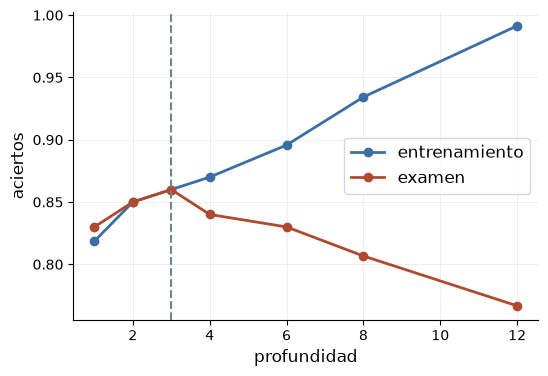

In [4]:
from sklearn.tree import DecisionTreeClassifier

profundidades = [1, 2, 3, 4, 6, 8, 12]
acc_train = []
acc_test = []

# ¿Qué va aquí? llenar las listas y graficar
for p in profundidades:
    arbol = DecisionTreeClassifier(max_depth=p, random_state=0).fit(X_train, y_train)
    acc_train.append(arbol.score(X_train, y_train))
    acc_test.append(arbol.score(X_test, y_test))
    print(f"profundidad {p:2d} | entrenamiento: {acc_train[-1]:.3f} | examen: {acc_test[-1]:.3f}")

mejor_p = profundidades[np.argmax(acc_test)]
print(f"Mejor profundidad en examen: {mejor_p} ({max(acc_test):.3f})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(profundidades, acc_train, "o-", color=AZUL, lw=2, label="entrenamiento")
ax.plot(profundidades, acc_test, "o-", color=ROJO, lw=2, label="examen")
ax.axvline(mejor_p, color=GRIS, ls="--")
ax.legend(fontsize=12)
ax.set_xlabel("profundidad", fontsize=12)
ax.set_ylabel("aciertos", fontsize=12)
eje_limpio(ax)

# Respuesta: elegiría profundidad 3. Ahí el examen llega a su máximo (0.86) y entrenamiento
# y examen van juntos (0.86 y 0.86). 

# Verificación (descomentar):
assert round(acc_test[2], 2) == 0.86      # profundidad 3
assert round(acc_train[6], 3) == 0.991 and round(acc_test[6], 3) == 0.767

### Ejercicio 3 (0.15): un árbol solo es inestable

Entrenar 25 árboles **sin límite de profundidad**, cada uno con 350 socios del entrenamiento elegidos al azar (`np.random.default_rng(s).choice(len(X_train), 350, replace=False)` con `s` de 0 a 24), y guardar sus aciertos en el examen. Reportar el mínimo y el máximo. De paso: imprimir la primera pregunta de los árboles con `s` de 0 a 3 (profundidad 2) y observar que esa sí es estable.

In [5]:
from sklearn.tree import export_text

aciertos = []
for s in range(25):
    # ¿Qué va aquí? submuestra de 350, árbol sin límite, score en examen
    idx = np.random.default_rng(s).choice(len(X_train), 350, replace=False)
    arbol = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])
    aciertos.append(arbol.score(X_test, y_test))

# imprimir min y max de aciertos
print(f"aciertos en examen | mínimo: {min(aciertos):.3f} | máximo: {max(aciertos):.3f}")

for s in range(4):
    idx = np.random.default_rng(s).choice(len(X_train), 350, replace=False)
    arbol2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])
    primera = export_text(arbol2, feature_names=columnas).splitlines()[0]
    print(f"s = {s} | primera pregunta: {primera.strip('|-- ')}")

# Verificación (descomentar):
assert round(min(aciertos), 3) == 0.73
assert round(max(aciertos), 3) == 0.8


# Respuesta: gana visitas <= 5, que baja la mezcla de 0.306 a 0.252; meses <= 12 solo la baja a 0.290.
# Sí coincide con el árbol de profundidad 1: su primera pregunta es visitas <= 5.50, que es el mismo
# corte porque las visitas son números enteros.

aciertos en examen | mínimo: 0.730 | máximo: 0.800
s = 0 | primera pregunta: visitas <= 5.50
s = 1 | primera pregunta: visitas <= 5.50
s = 2 | primera pregunta: visitas <= 5.50
s = 3 | primera pregunta: visitas <= 5.50


## Parte B · Elegir sin trampa (0.5 pt)

La sesión 16 en tres pasos: comparar candidatos con validación cruzada, afinar perillas con búsqueda, y tocar el examen una sola vez.

### Ejercicio 4 (0.20): tres candidatos, el mismo procedimiento

Comparar con validación cruzada estratificada de 5 pliegues (`StratifiedKFold(n_splits=5, shuffle=True, random_state=7)`) sobre el **entrenamiento**: logística (con escala, en Pipeline), árbol (`max_depth=4`) y kNN (con escala, `n_neighbors=15`). Imprimir promedio y desviación de cada uno. ¿Quién gana?

In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=7)
candidatos = {
    "logística": make_pipeline(StandardScaler(), LogisticRegression()),
    "árbol": DecisionTreeClassifier(max_depth=4, random_state=0),
    "kNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

promedios = {}
# ¿Qué va aquí? cross_val_score de cada candidato, guardar el promedio
# e imprimir promedio y desviación
for nombre, candidato in candidatos.items():
    puntajes = cross_val_score(candidato, X_train, y_train, cv=cv)
    promedios[nombre] = puntajes.mean()
    print(f"{nombre:10s} | promedio: {puntajes.mean():.3f} | desviación: {puntajes.std():.3f}")

ganador = max(promedios, key=promedios.get)
print(f"Gana: {ganador} ({promedios[ganador]:.3f})")

# Verificación (descomentar):
assert round(promedios["árbol"], 3) == 0.846
assert promedios["árbol"] == max(promedios.values())

logística  | promedio: 0.827 | desviación: 0.019
árbol      | promedio: 0.846 | desviación: 0.012
kNN        | promedio: 0.827 | desviación: 0.013
Gana: árbol (0.846)


### Ejercicio 5 (0.15): afinar las perillas del ganador

`GridSearchCV` sobre el árbol con `max_depth` en [2, 3, 4, 6] y `min_samples_leaf` en [5, 20, 50], usando el mismo `cv`. ¿Cuántas combinaciones probó? Imprimir la mejor y su puntaje.

In [7]:
from sklearn.model_selection import GridSearchCV

malla = {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [5, 20, 50]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=0), malla, cv=cv).fit(X_train, y_train)   # ¿Qué va aquí? GridSearchCV con la malla y cv, y fit sobre el entrenamiento

# imprimir best_params_, best_score_ y cuántas combinaciones probó
print(f"combinaciones probadas: {len(busqueda.cv_results_['params'])}")
print(f"mejor combinación: {busqueda.best_params_}")
print(f"mejor puntaje: {busqueda.best_score_:.3f}")

# Verificación (descomentar):
assert busqueda.best_params_ == {"max_depth": 3, "min_samples_leaf": 20}
assert round(busqueda.best_score_, 3) == 0.856

combinaciones probadas: 12
mejor combinación: {'max_depth': 3, 'min_samples_leaf': 20}
mejor puntaje: 0.856


### Ejercicio 6 (0.15): el examen se usa una vez

Tomar `busqueda.best_estimator_` (ya viene entrenado con los 700) y evaluarlo en el examen. Responder en un comentario: ¿por qué este número puede ser distinto del 0.856 anterior, y por qué no se vale seguir probando modelos después de verlo?

In [8]:
examen_final = busqueda.best_estimator_.score(X_test, y_test)   # ¿Qué va aquí?

print(f"simulacro (validación cruzada): {busqueda.best_score_:.3f} | examen: {examen_final:.3f}")

# Respuesta: ...
# Respuesta: el 0.856 es el promedio de 5 simulacros dentro de los 700 de entrenamiento, y con ese número elegí la mejor de 12 combinaciones, así que puede venir un poco inflado. 
# El 0.86 son 300 socios que nunca se usaron para elegir nada. Pueden diferir porque son datos distintos y el examen es una sola muestra de 300

# Verificación (descomentar):
assert round(examen_final, 3) == 0.86

simulacro (validación cruzada): 0.856 | examen: 0.860


## Parte C · El bosque (0.8 pt)

La sesión 17: si un árbol baila, que voten muchos. Bootstrap, bagging a mano, OOB e importancias.

### Ejercicio 7 (0.20): bagging a mano

Para B en [1, 5, 25, 100]: entrenar B árboles sin límite, cada uno con una muestra bootstrap (`np.random.default_rng(b).integers(0, len(X_train), len(X_train))` con `b` de 0 a B-1), sumar sus votos sobre el examen y clasificar por mayoría (`votos / B >= 0.5`). Guardar los aciertos en `aciertos_bagging` y graficar contra B.

B =   1 | aciertos en examen: 0.767
B =   5 | aciertos en examen: 0.787
B =  25 | aciertos en examen: 0.820
B = 100 | aciertos en examen: 0.823


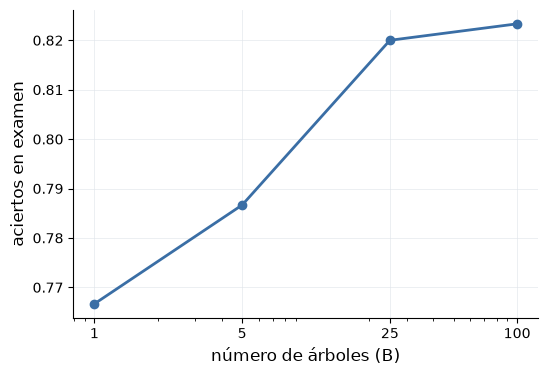

In [9]:
cantidades = [1, 5, 25, 100]
aciertos_bagging = []

# ¿Qué va aquí? el doble loop de votos, y la gráfica
for B in cantidades:
    votos = np.zeros(len(X_test))
    for b in range(B):
        idx = np.random.default_rng(b).integers(0, len(X_train), len(X_train))
        arbol = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])
        votos += arbol.predict(X_test)
    pred = (votos / B >= 0.5).astype(int)
    aciertos_bagging.append((pred == y_test).mean())
    print(f"B = {B:3d} | aciertos en examen: {aciertos_bagging[-1]:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cantidades, aciertos_bagging, "o-", color=AZUL, lw=2)
ax.set_xscale("log")
ax.set_xticks(cantidades, [str(B) for B in cantidades])
ax.set_xlabel("número de árboles (B)", fontsize=12)
ax.set_ylabel("aciertos en examen", fontsize=12)
eje_limpio(ax)

# Verificación (descomentar):
assert [round(a, 3) for a in aciertos_bagging] == [0.767, 0.787, 0.82, 0.823]

### Ejercicio 8 (0.20): las perillas del bosque, medidas con OOB

Para `min_samples_leaf` en [1, 5, 10, 20, 50]: RandomForest de 300 árboles con `oob_score=True` (`random_state=0, n_jobs=-1`), guardar el OOB de cada uno en el diccionario `oobs`. Elegir el mejor y reportar su examen. Todo sin usar el examen para elegir: para eso está el OOB.

In [10]:
from sklearn.ensemble import RandomForestClassifier

oobs = {}
# ¿Qué va aquí? el loop con oob_score=True
for msl in [1, 5, 10, 20, 50]:
    bosque = RandomForestClassifier(n_estimators=300, min_samples_leaf=msl, oob_score=True,
                                    random_state=0, n_jobs=-1).fit(X_train, y_train)
    oobs[msl] = bosque.oob_score_
    print(f"min_samples_leaf = {msl:2d} | OOB: {oobs[msl]:.3f}")

mejor_msl = max(oobs, key=oobs.get)      # la perilla con mayor OOB
bosque_final = RandomForestClassifier(n_estimators=300, min_samples_leaf=mejor_msl,
                                      random_state=0, n_jobs=-1).fit(X_train, y_train)
examen_bosque = bosque_final.score(X_test, y_test)  # reentrenar con la ganadora (sin oob) y evaluar en examen

print(f"mejor min_samples_leaf: {mejor_msl} | examen: {examen_bosque:.3f}")

# Verificación (descomentar):
assert mejor_msl == 5 and round(oobs[5], 3) == 0.857
assert round(examen_bosque, 3) == 0.86

min_samples_leaf =  1 | OOB: 0.831
min_samples_leaf =  5 | OOB: 0.857
min_samples_leaf = 10 | OOB: 0.856
min_samples_leaf = 20 | OOB: 0.846
min_samples_leaf = 50 | OOB: 0.811
mejor min_samples_leaf: 5 | examen: 0.860


### Ejercicio 9 (0.20): la señal arriba, el ruido abajo

Agregar al entrenamiento una columna `ruido` de puro azar (`np.random.default_rng(9).normal(0, 1, len(X_train))`), entrenar un bosque (300 árboles, `min_samples_leaf=20`, `random_state=0`) y ordenar las importancias de mayor a menor. ¿Dónde quedó el ruido?

In [11]:
X_train_ruido = X_train.copy()
X_train_ruido["ruido"] = np.random.default_rng(9).normal(0, 1, len(X_train))

bosque_ruido = RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                      random_state=0, n_jobs=-1).fit(X_train_ruido, y_train)
importancias = pd.Series(bosque_ruido.feature_importances_,
                         index=X_train_ruido.columns).sort_values(ascending=False)   # ¿Qué va aquí? Series ordenada con feature_importances_

print(importancias.round(3))

# Verificación (descomentar):
assert importancias.index[0] == "visitas" and importancias.index[-1] == "ruido"
assert round(importancias["ruido"], 3) == 0.091


# El ruido quedó de último (0.091), debajo de visitas (0.562), meses (0.236) y cuota (0.111).
# Pero no es cero: el bosque le encuentra cortes por puro azar, y la cuota queda apenas arriba del ruido.


visitas    0.562
meses      0.236
cuota      0.111
ruido      0.091
dtype: float64


### Ejercicio 10 (0.20): un árbol contra un bosque, diez veces

Repetir 10 veces (repartos `train_test_split` con `random_state` de 0 a 9): entrenar un árbol sin límite y un bosque (200 árboles, `min_samples_leaf=20`) y guardar los aciertos de examen de cada uno. Reportar mínimo y máximo de cada modelo. ¿Qué se observa?

In [12]:
arbol_res = []
bosque_res = []

for s in range(10):
    # ¿Qué va aquí? nuevo reparto con random_state=s, entrenar ambos, guardar scores
    Xa, Xb, ya, yb = train_test_split(df[columnas], df["se_va"], test_size=0.3, random_state=s)
    arbol = DecisionTreeClassifier(random_state=0).fit(Xa, ya)
    bosque = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                    random_state=0, n_jobs=-1).fit(Xa, ya)
    arbol_res.append(arbol.score(Xb, yb))
    bosque_res.append(bosque.score(Xb, yb))

# imprimir min/max de cada uno
print(f"árbol  | mínimo: {min(arbol_res):.3f} | máximo: {max(arbol_res):.3f}")
print(f"bosque | mínimo: {min(bosque_res):.3f} | máximo: {max(bosque_res):.3f}")
# Respuesta: ...

# Verificación (descomentar):
assert round(min(arbol_res), 3) == 0.71 and round(max(arbol_res), 3) == 0.8
assert round(min(bosque_res), 3) == 0.82 and round(max(bosque_res), 3) == 0.88

# Respuesta: el árbol sin límite baila de 0.71 a 0.80 según el reparto, el bosque va de 0.82 a 0.88 y además es más alto (promedio 0.849 contra 0.769).

árbol  | mínimo: 0.710 | máximo: 0.800
bosque | mínimo: 0.820 | máximo: 0.880


## Parte D · Criterio (0.2 pt)

### Ejercicio 11 (0.20)

Dos preguntas, 2-3 líneas cada una, **citando los números obtenidos**:

**(a)** El 0.856 del ejercicio 5 y el 0.86 del ejercicio 6 se parecen, pero no son intercambiables. Explicar qué es cada número, cuál se reporta a gerencia y por qué el examen se usa una sola vez.

**(b)** El gimnasio va a desplegar un modelo para llamar a socios en riesgo. Con los resultados de los ejercicios 8 a 10, ¿árbol o bosque? Dar el argumento con números, y mencionar qué se pierde a cambio.

_(Responder editando esta celda)_

**Respuesta (a):**  El 0.856 es el promedio de la validación cruzada de 5 pliegues sobre los 700 de entrenamiento. Es el simulacro El 0.86 es el examen, 300 socios que no se tocaron para elegir nada.  A gerencia se le reporta el 0.86, porque es la única estimación honesta de cómo le irá al modelo con socios nuevos. Se usa una sola vez porque, si lo uso para volver a elegir, deja de ser examen y se convierte en otro simulacro.

**Respuesta (b):** Es mejor el bosque. El árbol baila entre 0.71 y 0.80 según el reparto, mientras que el bosque se queda entre 0.82 y 0.88 (promedio 0.849 contra 0.769). Además se afina sin tocar el examen gracias al OOB  Lo que se pierde es la explicación, un árbol se lee como reglas ("visita 5 veces o menos y lleva menos de un año") que el gerente entiende y puede usar al llamar al socio. El bosque son 300 árboles votando, dice qué columnas importan pero no por qué se marcó a un socio en particular.

## Bitácora de AI (opcional, no penaliza)

Si se usó AI para entender algún concepto, anotar aquí qué se preguntó y qué se entendió. Si no se usó, escribir "No se usó".

- **Ejercicio 1:** usé AI (Claude) para guiarme y resolver errores. Me explicó la idea de la mezcla de un corte: separar `y_train` con la máscara `lado` y su inversa `~lado`, contar en cada lado los que se van (`.sum()`) y los que se quedan, y promediar las dos mezclas ponderando por el tamaño de cada lado. . También había calculado `m_total` con `mezcla_del_corte("visitas", 5)`, que es un corte, y no con `mezcla` sobre todo `y_train`; por eso salía 0.252 en vez de 0.306. Entendí que gana el corte con la mezcla más baja (no la más alta) y que `m_total` es el punto de partida, no un candidato. Para elegir el ganador automáticamente usé `min(cortes, key=cortes.get)` sobre un diccionario.
- **Ejercicio 3:** usé AI (Claude) para entender cómo escribir la línea `arbol = DecisionTreeClassifier(random_state=0).fit(X_train.iloc[idx], y_train.iloc[idx])` y qué hace cada parte. `DecisionTreeClassifier()` crea el árbol; al no ponerle `max_depth` crece sin límite, que es lo que pide el ejercicio. `random_state=0` fija el azar interno del árbol (el desempate entre cortes igual de buenos), para que el resultado sea siempre el mismo y las verificaciones sean exactas.